In [1]:
from IPython.display import display, HTML
display(HTML("<style>.container{width:95% !important;}</style>"))

# 1. Import Libraries

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# Set plot style
sns.set(style="whitegrid")
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

C:\Users\sreek\anaconda3\lib\site-packages\pandas\core\computation\expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\sreek\anaconda3\lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.2' currently installed).
  from pandas.core import (


# 2. Load Dataset

In [ ]:
df = pd.read_csv("https://raw.githubusercontent.com/srinikethakella1812/Neural_Network/refs/heads/main/bank-full.csv")
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


# 3. Data Pre-processing

## 3.1 Data Summary

In [4]:
print(df.shape)

(45211, 17)


In [5]:
data_types = df.dtypes.astype(str)

df_summ = pd.concat({'DataType': data_types,
                     'Unique': df.nunique(),
                     'Count': df.count().round(1),
                     'Null': df.isnull().sum(),
                     'Zero': (df==0).sum(),
                     'Min': df.select_dtypes(include=[np.number]).min().round(1),
                     '25%': df.select_dtypes(include=[np.number]).quantile(0.25).round(1),
                     'Mean': df.select_dtypes(include=[np.number]).mean().round(1),
                     'Median': df.select_dtypes(include=[np.number]).median().round(1),
                     '75%': df.select_dtypes(include=[np.number]).quantile(0.75).round(1),
                     'Max': df.select_dtypes(include=[np.number]).max().round(1),
                     '-ve': (df.select_dtypes(include=[np.number])<0).sum(),          
                    }, axis=1)

df_summ.head(20)

,DataType,Unique,Count,Null,Zero,Min,25%,Mean,Median,75%,Max,-ve
age,int64,77,45211,0,0,18.0,33.0,40.9,39.0,48.0,95.0,0.0
job,object,12,45211,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,object,3,45211,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,object,4,45211,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,object,2,45211,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,int64,7168,45211,0,3514,-8019.0,72.0,1362.3,448.0,1428.0,102127.0,3766.0
housing,object,2,45211,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,object,2,45211,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,object,3,45211,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,int64,31,45211,0,0,1.0,8.0,15.8,16.0,21.0,31.0,0.0


- The dataset contains approximately 45,211 rows and 17 columns (features).

- There are a mix of numerical features (e.g., age, balance, duration) and categorical features (e.g., job, education, poutcome).

- There are no Null values present.

- "balance" and "previous" features contain high number of zeroes.

- "balance" and "pdays" feature contain negative values.

## 3.2 Data consistency check

In [6]:
# --- Checking for Inconsistent Numeric Data in 'object' Columns ---

# Select only object (string) columns
object_cols = df.select_dtypes(include=['object']).columns

# Initialize a dictionary to store the results
results = {}

for col in object_cols:
    
    # Attempt to coerce the entire column to numeric. 
    # If a value cannot be parsed as a number (e.g., 'abc'), it becomes NaN.
    coerced_series = pd.to_numeric(df[col], errors='coerce')
    
    # Identify values that successfully converted (they were numeric-like)
    is_numeric = coerced_series.notna()
    
    # Store the analysis results
    results[col] = {'Numeric-Like Count': is_numeric.sum()}

# Convert results dictionary to a DataFrame for clean output
consistency_check_df = pd.DataFrame(results).T

print("Data Consistency Check for Object Columns:")

# Rename columns and format percentage for clean display
consistency_check_df = consistency_check_df.rename(columns={
    'Numeric-Like Count': 'Count (Numeric/String-Number)',
})

consistency_check_df.head(10)

Data Consistency Check for Object Columns:


,Count (Numeric/String-Number)
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
poutcome,0
y,0


In [7]:
# continuous vs categorical arrays
num_cols = ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']
cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'poutcome']
time_cols = ['day', 'month']

# 4. EDA

## 4.1 Univariate analysis

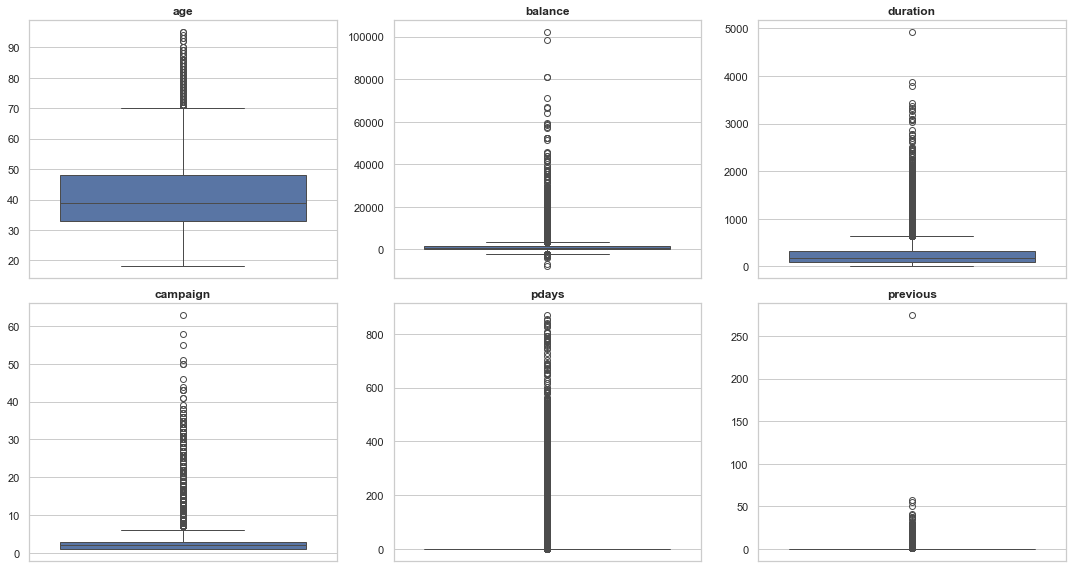

In [8]:
# Numerical variables - Box plots

fig, axs = plt.subplots(ncols=3, nrows=2, figsize=(15, 8))
index = 0
axs = axs.flatten()

for i,col in enumerate(num_cols):
    sns.boxplot(y=col, data=df, ax=axs[i])
    axs[i].set_ylabel('')
    axs[i].set_title(col, fontweight='bold')
    
# Remove any unused subplots
for j in range(len(num_cols), len(axs)):
    fig.delaxes(axs[i])
    
plt.tight_layout()
plt.show()

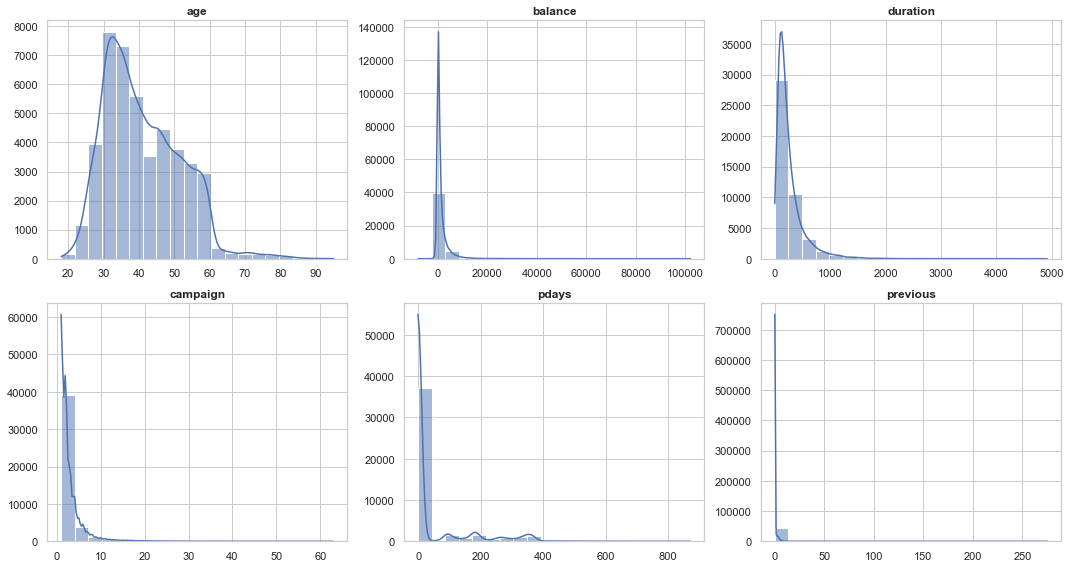

In [9]:
# Numerical variables - Distribution plots

fig, axs = plt.subplots(ncols=3, nrows=2, figsize=(15, 8))
index = 0
axs = axs.flatten()

for i,col in enumerate(num_cols):
    sns.histplot(x=col, data=df, bins=20, kde=True, ax=axs[i])
    axs[i].set_xlabel('')
    axs[i].set_ylabel('')
    axs[i].set_title(col, fontweight='bold')
    
# Remove any unused subplots
for i in range(len(num_cols), len(axs)):
    fig.delaxes(axs[i])
    
plt.tight_layout()
plt.show()

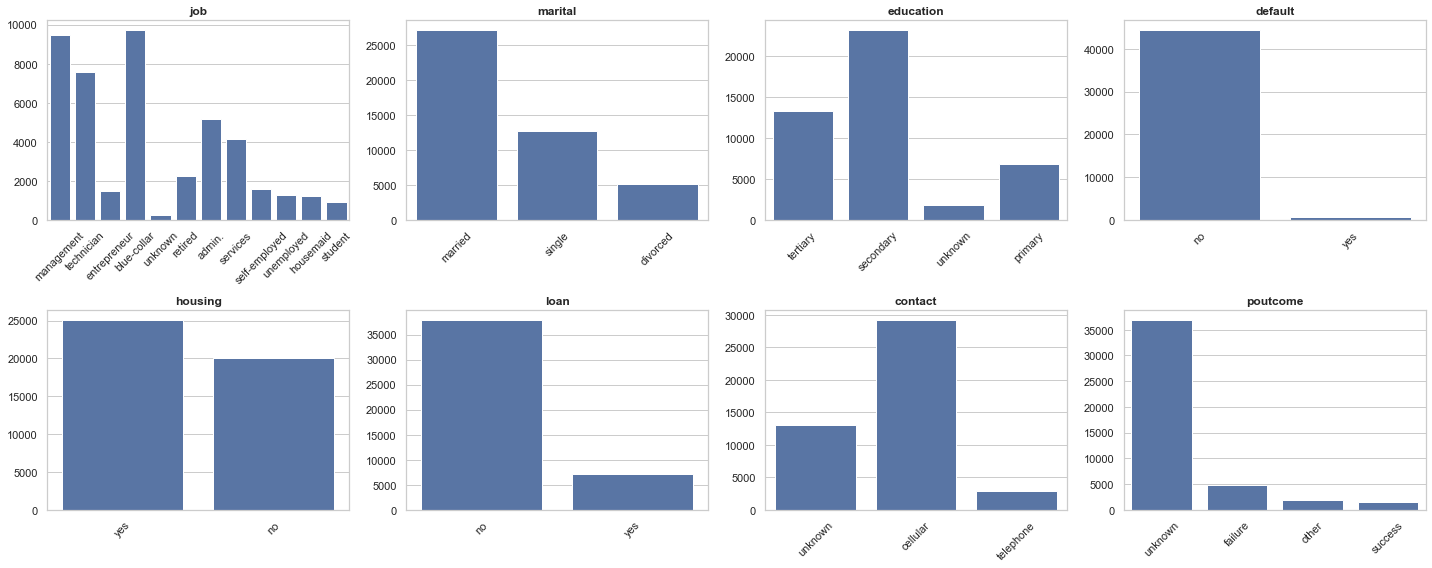

In [10]:
# Categorical variables - Bar charts

fig, axs = plt.subplots(ncols=4, nrows=2, figsize=(20,8))
index = 0
axs = axs.flatten()

for i,col in enumerate(cat_cols):
    sns.countplot(x=col, data=df, ax=axs[i])
    axs[i].set_xlabel('')
    axs[i].set_ylabel('')
    axs[i].set_title(col, fontweight='bold')
    
    axs[i].tick_params(axis='x', rotation=45)
    
    
# Remove any unused subplots
for i in range(len(cat_cols), len(axs)):
    fig.delaxes(axs[i])

plt.tight_layout()
plt.show()

## 4.2 Bivariate Analysis

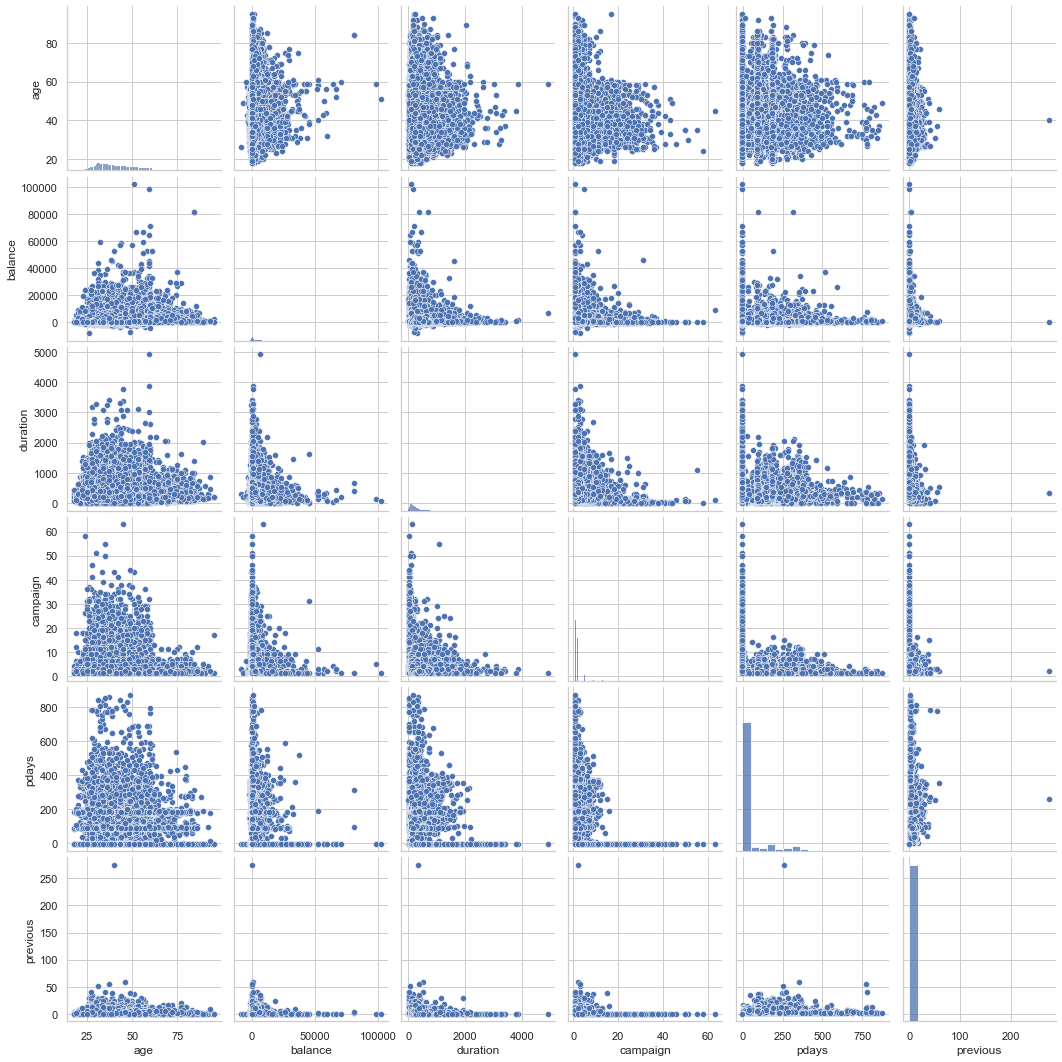

In [11]:
# Numerical variables - Scatter plots

sns.pairplot(data=df[num_cols])
plt.show()

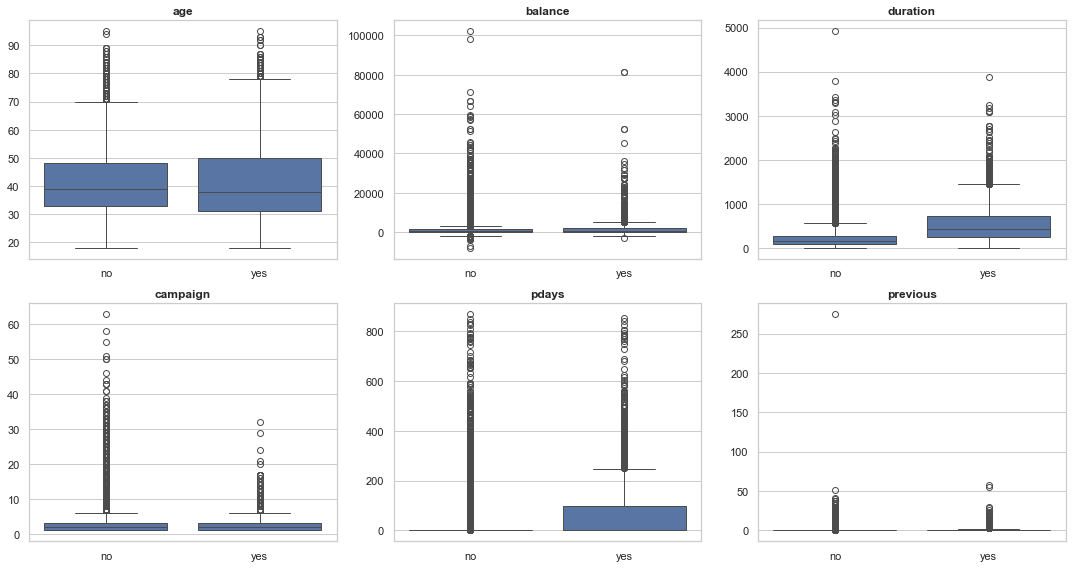

In [12]:
# Numerical variables vs Target - Box plots

y_col = num_cols

x_col = ['y']

df_tar = df[y_col + x_col]

fig, axs = plt.subplots(ncols=3, nrows=2, figsize=(15, 8))
index = 0
axs = axs.flatten()

for i,col in enumerate(y_col):
    sns.boxplot(y=col, x='y', data=df_tar, ax=axs[i])
    axs[i].set_ylabel('')
    axs[i].set_xlabel('')
    axs[i].set_title(col, fontweight='bold')
    
    axs[i].tick_params(axis='x')
    
     
# Remove any unused subplots
for i in range(len(y_col), len(axs)):
    fig.delaxes(axs[i])
    
plt.tight_layout()
plt.show()

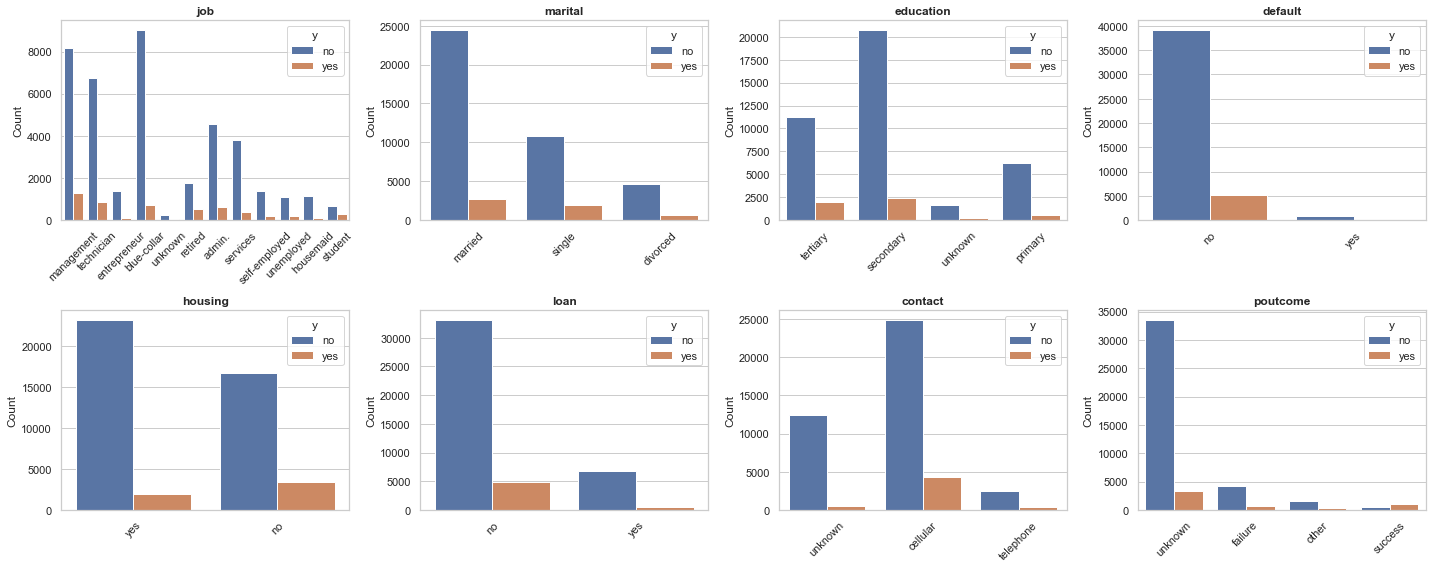

In [13]:
# Categorical variables vs Target variable - Bar charts

fig, axs = plt.subplots(ncols=4, nrows=2, figsize=(20, 8))
axs = axs.flatten()

for i, col in enumerate(cat_cols):
    sns.countplot(x=col, hue='y', data=df, ax=axs[i])
    
    axs[i].set_xlabel('')
    axs[i].set_ylabel('Count')
    axs[i].set_title(col, fontweight='bold')
    
    axs[i].tick_params(axis='x', rotation=45)
    
    
# Remove any unused subplots (if your cat_cols length changes)
for i in range(len(cat_cols), len(axs)):
    fig.delaxes(axs[i])

plt.tight_layout()
plt.show()

- Severe Target Imbalance: Visual exploration of the target variable y uncovers a highly disproportional class distribution.

- Continuous Variance Boundaries: Univariate box plots expose massive scale discrepancies and heavy-tailed distributions; for instance, the balance attribute spans from negative overdrawn bounds to values exceeding $\$100,000$.

# 5. Feature Engineering

## 5.1 Outlier Treatment

In [14]:
# Define features prone to extreme outliers identified in EDA
outlier_cols = ['balance', 'duration', 'campaign']

print("Before Outlier Treatment (Max Values):")
print(df[outlier_cols].max())

# Apply capping (Winsorization) at 1st and 99th percentiles
for col in outlier_cols:
    lower_bound = df[col].quantile(0.01)
    upper_bound = df[col].quantile(0.99)
    df[col] = np.clip(df[col], lower_bound, upper_bound)

print("\nAfter Outlier Treatment (Max Values capped at 99th percentile):")
print(df[outlier_cols].max())

Before Outlier Treatment (Max Values):
balance     102127
duration      4918
campaign        63
dtype: int64

After Outlier Treatment (Max Values capped at 99th percentile):
balance     13164.9
duration     1269.0
campaign       16.0
dtype: float64


## 5.2 Interaction features

In [15]:
# Isolate the 'never contacted' flag from continuous pdays
df['never_contacted'] = (df['pdays'] == -1).astype(int)

# Call Efficiency - Duration per Campaign Contact
df['duration_per_campaign'] = df['duration'] / (df['campaign'] + 1e-5)

# Financial Stability Score - Helps the ANN understand financial capacity relative to the customer's age demographic.
df['balance_age_ratio'] = df['balance'] / df['age']

# Historical Engagement Multiplier - For customers never contacted before, this cleanly defaults to 0 using the mask indicator.
df['past_campaign_engagement'] = np.where(df['never_contacted'] == 1,0, df['previous'] * df['pdays'])

## 5.3 One-hot (Nominal) Encoding
Unordered categorical variables are expanded into binary columns

In [16]:
# 1. Identify the top 4 most frequent job categories
top_4_jobs = df['job'].value_counts().nlargest(4).index.tolist()
print("Top 4 job categories being kept:", top_4_jobs)

# 2. Create the new variable by grouping the remaining categories into 'Other'
df['job_grp'] = df['job'].apply(lambda x: x if x in top_4_jobs else 'Other')

# 3. Drop the original 'job' variable from the DataFrame
df.drop(columns=['job'], inplace=True)

Top 4 job categories being kept: ['blue-collar', 'management', 'technician', 'admin.']


In [17]:
cat_cols = ['job_grp', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'poutcome']

In [18]:
df = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

## 5.4 Target variable

In [19]:
# Convert 'no' to 0 and 'yes' to 1

df['y'] = df['y'].map({'no': 0, 'yes': 1}).astype(int)

print(f"1 class pct: {100*df['y'].mean():.2f} %")

1 class pct: 11.70 %


In [20]:
# df_final = df.dropna().copy()

df.head()

,age,balance,day,month,duration,campaign,pdays,previous,y,never_contacted,...,education_tertiary,education_unknown,default_yes,housing_yes,loan_yes,contact_telephone,contact_unknown,poutcome_other,poutcome_success,poutcome_unknown
0,58,2143.0,5,may,261,1,-1,0,0,1,...,1,0,0,1,0,0,1,0,0,1
1,44,29.0,5,may,151,1,-1,0,0,1,...,0,0,0,1,0,0,1,0,0,1
2,33,2.0,5,may,76,1,-1,0,0,1,...,0,0,0,1,1,0,1,0,0,1
3,47,1506.0,5,may,92,1,-1,0,0,1,...,0,1,0,1,0,0,1,0,0,1
4,33,1.0,5,may,198,1,-1,0,0,1,...,0,1,0,0,0,0,1,0,0,1


- Applied two-sided Winsorization capping at the 1st and 99th percentiles to compress extreme multi-sigma outliers without discarding valuable training records.

- Cardinality Mitigation: To prevent an explosion of sparse columns during subsequent dummy variable creation, the high-cardinality job field was optimized by grouping sparse profiles into an 'Other' domain while cleanly retaining the top 4 dominant sectors.

- Capturing Non-Linear Interaction: Three domain-specific interaction metrics (duration_per_campaign, balance_age_ratio, and past_campaign_engagement) were introduced to explicitly map financial stability and campaign interaction trends for the ANN layers.

- Target Class imbalance: approximately $88.3\%$ of the customer base rejected the offer, and only a minority flight of $\approx 11.7\%$ subscribed.

# 6. Modeling

## 6.1 Split Dataset into Train/Test

In [21]:
X = df.drop(time_cols + ['y'], axis=1)
y = df['y']

# Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

## 6.2 Feature scaling

In [22]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 6.3 Baseline model - Logistic Regression

In [23]:
baseline_model = LogisticRegression(max_iter=1000, random_state=42)

baseline_model.fit(X_train_scaled, y_train)

baseline_preds = baseline_model.predict(X_test_scaled)
baseline_probs = baseline_model.predict_proba(X_test_scaled)[:, 1]

print("\nLog Reg Classification Report:")
print(classification_report(y_test, baseline_preds))
print(f"Area Under ROC Curve: {roc_auc_score(y_test, baseline_probs):.3f}")


Log Reg Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.97      0.94      7985
           1       0.63      0.33      0.43      1058

    accuracy                           0.90      9043
   macro avg       0.77      0.65      0.69      9043
weighted avg       0.88      0.90      0.88      9043

Area Under ROC Curve: 0.891


## 6.4 Initial Model Comparison - Feedforward Neural Network

In [24]:
ann_model = MLPClassifier(
                    hidden_layer_sizes=(8, 8), 
                    activation='logistic', 
                    solver='adam', 
                    max_iter=500, 
                    random_state=42)

ann_model.fit(X_train_scaled, y_train)

ann_preds = ann_model.predict(X_test_scaled)
ann_probs = ann_model.predict_proba(X_test_scaled)[:, 1]

print("\nANN Classification Report:")
print(classification_report(y_test, ann_preds, target_names=['No Sub', 'Subscribed']))

print(f"Area Under ROC Curve: {roc_auc_score(y_test, ann_probs):.3f}")


ANN Classification Report:
              precision    recall  f1-score   support

      No Sub       0.92      0.97      0.95      7985
  Subscribed       0.62      0.38      0.47      1058

    accuracy                           0.90      9043
   macro avg       0.77      0.68      0.71      9043
weighted avg       0.89      0.90      0.89      9043

Area Under ROC Curve: 0.896


## 6.5 Hyperparameter tuning

In [25]:
ann_tuned_model = MLPClassifier(
                    hidden_layer_sizes=(16, 8), 
                    activation='relu', 
                    solver='adam', 
                    max_iter=500,
                    random_state=42)

ann_tuned_model.fit(X_train_scaled, y_train)

ann_tuned_preds = ann_tuned_model.predict(X_test_scaled)
ann_tuned_probs = ann_tuned_model.predict_proba(X_test_scaled)[:, 1]

print("\nANN Classification Report:")
print(classification_report(y_test, ann_tuned_preds, target_names=['No Sub', 'Subscribed']))

print(f"Area Under ROC Curve: {roc_auc_score(y_test, ann_tuned_probs):.3f}")


ANN Classification Report:
              precision    recall  f1-score   support

      No Sub       0.92      0.97      0.94      7985
  Subscribed       0.61      0.40      0.49      1058

    accuracy                           0.90      9043
   macro avg       0.77      0.68      0.71      9043
weighted avg       0.89      0.90      0.89      9043

Area Under ROC Curve: 0.896


## 6.6 K-Fold Cross-Validation

In [26]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = []

print("Executing 5-Fold Stratified Cross-Validation for Sklearn MLP...")
for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), 1):
    # Split
    X_tr, X_va = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_va = y.iloc[train_idx], y.iloc[val_idx]
    
    # FIX: Instantiate a fresh scaler inside the fold loop to prevent leakage
    fold_scaler = StandardScaler()
    X_tr_scaled = fold_scaler.fit_transform(X_tr)
    X_va_scaled = fold_scaler.transform(X_va)
    
    # Fit model
    fold_mlp = MLPClassifier(hidden_layer_sizes=(16, 8), activation='relu', 
                             solver='adam', max_iter=500, random_state=42)
    fold_mlp.fit(X_tr_scaled, y_tr)
    
    # Evaluate
    probs = fold_mlp.predict_proba(X_va_scaled)[:, 1]
    auc = roc_auc_score(y_va, probs)
    cv_scores.append(auc)
    print(f"Fold {fold} ROC-AUC: {auc:.4f}")

print(f"\nMean CV ROC-AUC Score: {np.mean(cv_scores):.4f} (+/- {np.std(cv_scores):.4f})")

Executing 5-Fold Stratified Cross-Validation for Sklearn MLP...
Fold 1 ROC-AUC: 0.9018
Fold 2 ROC-AUC: 0.8998
Fold 3 ROC-AUC: 0.8972
Fold 4 ROC-AUC: 0.9027
Fold 5 ROC-AUC: 0.8938

Mean CV ROC-AUC Score: 0.8991 (+/- 0.0032)


## 6.7 Feature Importance Analysis

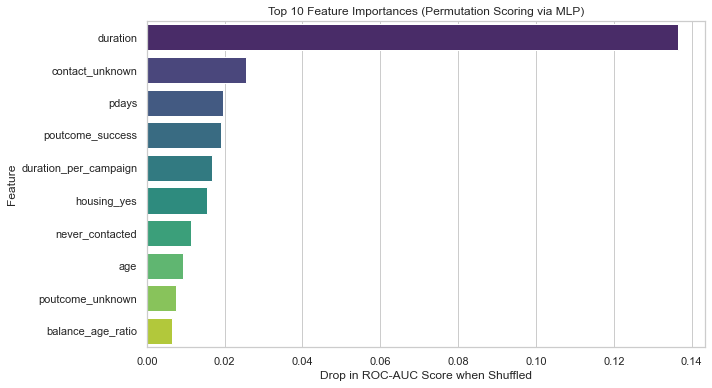

In [27]:
from sklearn.inspection import permutation_importance

# Use the scikit-learn MLP model for permutation calculation
result = permutation_importance(
    ann_tuned_model, X_test_scaled, y_test, 
    scoring='roc_auc', n_repeats=5, random_state=42
)

# Organize into a DataFrame
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance_Score': result.importances_mean
}).sort_values(by='Importance_Score', ascending=False)

# Plot Feature Importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance_Score', y='Feature', data=importance_df.head(10), palette='viridis')
plt.title('Top 10 Feature Importances (Permutation Scoring via MLP)')
plt.xlabel('Drop in ROC-AUC Score when Shuffled')
plt.show()

- Executed a stratified 80/20 data split to lock in identical class proportions across both partitions, followed by strict localized z-score standardization.
- Baseline classification performance benchmarks were established via a Logistic Regression architecture, yielding an initial area under the ROC curve of 0.891.
- Developed an initial Scikit-Learn Multilayer Perceptron (MLP) utilizing dual-hidden layers of size (8, 8) and a logistic activation framework.
- Outperformed the traditional baseline performance slightly, advancing the Area Under the ROC Curve metric to 0.896.
- Adjusted hidden layer densities to a single 16-node layer while switching the activation backbone to Rectified Linear Units (relu) to accelerate convergence.
- Evaluated classification precision and recall trade-offs, holding the overall ROC-AUC steady at 0.896 while observing variations in minority class capture.
- Standardized performance tracking by wrapping the Multilayer Perceptron inside a rigorous 5-Fold Stratified Cross-Validation framework.
- Evaluated out-of-sample model reliability, yielding a stable mean CV ROC-AUC score of 0.8991 with a minimal standard deviation of $\pm 0.0032$.
- Calculated model-agnostic Permutation Importance scores across the test partition to isolate features driving the network's predictive decisions.
- Confirmed that call duration, unknown contact methods, and past campaign timelines (pdays) represent the dominant predictive drivers within the data matrix.

## 6.8 Advanced Framework: TensorFlow/Keras Architecture

In [28]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

# Ensure reproducibility
tf.random.set_seed(42)

# Build a customized deep network architecture
keras_model = Sequential([
    # Input Layer + First Hidden Layer
    Dense(32, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    BatchNormalization(),
    Dropout(0.3),  # Explicit Dropout to prevent overfitting
    
    # Second Hidden Layer
    Dense(16, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),
    
    # Output Layer for Binary Classification
    Dense(1, activation='sigmoid')
])

# Compile model tracking Binary Crossentropy and Area Under ROC
keras_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=[tf.keras.metrics.AUC(name='roc_auc')]
)

# Define Early Stopping callback to watch validation loss
early_stop = EarlyStopping(
    monitor='val_loss', 
    patience=10, 
    restore_best_weights=True,
    verbose=1
)

# Train the advanced network
history = keras_model.fit(
    X_train_scaled, y_train,
    validation_split=0.15, # Internal validation split to analyze convergence
    epochs=100,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
481/481 [==============================] - 3s 3ms/step - loss: 0.4607 - roc_auc: 0.7229 - val_loss: 0.2679 - val_roc_auc: 0.8799
Epoch 2/100
481/481 [==============================] - 1s 3ms/step - loss: 0.2836 - roc_auc: 0.8347 - val_loss: 0.2424 - val_roc_auc: 0.8927
Epoch 3/100
481/481 [==============================] - 1s 3ms/step - loss: 0.2642 - roc_auc: 0.8584 - val_loss: 0.2378 - val_roc_auc: 0.8951
Epoch 4/100
481/481 [==============================] - 1s 3ms/step - loss: 0.2551 - roc_auc: 0.8720 - val_loss: 0.2371 - val_roc_auc: 0.8961
Epoch 5/100
481/481 [==============================] - 1s 3ms/step - loss: 0.2516 - roc_auc: 0.8751 - val_loss: 0.2346 - val_roc_auc: 0.8988
Epoch 6/100
481/481 [==============================] - 1s 3ms/step - loss: 0.2478 - roc_auc: 0.8806 - val_loss: 0.2325 - val_roc_auc: 0.9004
Epoch 7/100
481/481 [==============================] - 2s 4ms/step - loss: 0.2437 - roc_auc: 0.8853 - val_loss: 0.2328 - val_roc_auc: 0.9002
Epoch 8/100
4

481/481 [==============================] - 1s 3ms/step - loss: 0.2291 - roc_auc: 0.9018 - val_loss: 0.2259 - val_roc_auc: 0.9058
Epoch 58: early stopping


## 6.9 Keras Evaluation & Metrics Compilation

283/283 [==============================] - 1s 1ms/step
              precision    recall  f1-score   support

      No Sub       0.91      0.98      0.95      7985
  Subscribed       0.65      0.31      0.42      1058

    accuracy                           0.90      9043
   macro avg       0.78      0.65      0.68      9043
weighted avg       0.88      0.90      0.88      9043

Final Test ROC-AUC Score: 0.9002


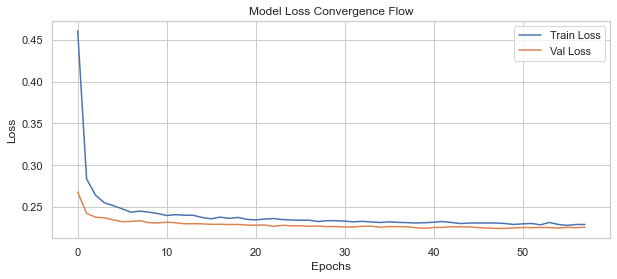

In [29]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# Generate predictions (probabilities and hard classes)
keras_probs = keras_model.predict(X_test_scaled).flatten()
keras_preds = (keras_probs >= 0.5).astype(int)

print(classification_report(y_test, keras_preds, target_names=['No Sub', 'Subscribed']))
print(f"Final Test ROC-AUC Score: {roc_auc_score(y_test, keras_probs):.4f}")

# Plot Convergence History
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 4))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss Convergence Flow')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

- Built an advanced sequential deep neural network utilizing modern regularization mechanisms including BatchNormalization and explicit Dropout layers.
- Integrated an EarlyStopping execution callback tied directly to val_loss changes, successfully terminating execution at epoch 58 to lock in optimal model parameters.
- Extracted final test data predictions using a standard 0.5 probability decision threshold, yielding a peak classification Area Under the ROC Curve of 0.9002.
- Visualized historical loss trajectories across training cycles to confirm stable convergence patterns and check for underlying overfitting.